# Assignment 4 – Bias mitigation with Reweighing

**Algorithm:** Reweighing (pre-processing) from Kamiran & Calders (2012), *Data preprocessing techniques for classification without discrimination*, KAIS 33(1).

**Datasets:** Adult (sensitive attribute: sex), German Credit (age > 25), COMPAS (race).

**Pipeline per dataset**

1. Load and clean the data; encode the sensitive attribute `s` (1 = privileged, 0 = unprivileged) and the label `y` (1 = favourable outcome).
2. Compute DP_Diff, DIR and consistency on the **original labels** (before any split, mitigation or training).
3. Stratified train/test split.
4. Reweighing on the **training set only** (AIF360 `Reweighing`), then train a logistic regression with the instance weights. As in the main setting of the paper (assumption A2), the sensitive attribute is used to compute the weights and to evaluate fairness, but it is **not a feature of the classifier**.
5. On the held-out test set, compute DP_Diff, DIR, consistency, accuracy and balanced accuracy from the final predictions.
6. Compare before and after mitigation (original labels, unweighted baseline classifier, reweighed classifier).

**Metric definitions** (AIF360 conventions)

- `DP_Diff = P(ŷ=1 | unprivileged) − P(ŷ=1 | privileged)`; 0 is ideal, negative means the unprivileged group is disadvantaged.
- `DIR = P(ŷ=1 | unprivileged) / P(ŷ=1 | privileged)`; 1 is ideal.
- `Consistency = 1 − mean_i | ŷ_i − mean(ŷ of the k nearest neighbours of i) |`, k = 5; 1 is ideal.

In [1]:
# Uncomment on first run:
# !pip install aif360 scikit-learn pandas numpy matplotlib

In [2]:
import os
import urllib.request
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, balanced_accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore")

# ---- parameter settings (report these) ----
SEED = 42            # random seed of the main run
TEST_SIZE = 0.30     # 70/30 stratified split
N_NEIGHBORS = 5      # k for the consistency measure (AIF360 default)
N_REPEATS = 10       # number of seeds in the robustness check
DATA_DIR = "data"    # raw files are downloaded here
LR_PARAMS = dict(C=1.0, max_iter=2000, solver="lbfgs")
# Assumption A2 of the paper: the classifier must not use the sensitive attribute S for prediction.
# S is used only to compute the Reweighing weights (training) and to evaluate fairness.
USE_S_AS_FEATURE = False

try:
    from aif360.datasets import BinaryLabelDataset
    from aif360.algorithms.preprocessing import Reweighing
    from aif360.metrics import BinaryLabelDatasetMetric
    HAVE_AIF360 = True
except Exception as e:  # the notebook still runs with the manual implementation
    HAVE_AIF360 = False
    print("AIF360 not available, using the manual Reweighing implementation:", e)

print("AIF360 available:", HAVE_AIF360)

pip install 'aif360[AdversarialDebiasing]'
pip install 'aif360[AdversarialDebiasing]'
pip install 'aif360[Reductions]'
pip install 'aif360[Reductions]'
pip install 'aif360[inFairness]'
pip install 'aif360[Reductions]'


AIF360 available: True


## 1. Data loading

Each loader returns a DataFrame with the feature columns plus two extra columns: `s` (sensitive attribute, 1 = privileged) and `y` (label, 1 = favourable).
Raw files are downloaded once into `data/`. If a download fails, place the file there manually (URLs are in the code).

In [3]:
URLS = {
    "adult.data": "https://archive.ics.uci.edu/ml/machine-learning-databases/adult/adult.data",
    "german.data": "https://archive.ics.uci.edu/ml/machine-learning-databases/statlog/german/german.data",
    "compas-scores-two-years.csv": "https://raw.githubusercontent.com/propublica/compas-analysis/master/compas-scores-two-years.csv",
}

def fetch(filename):
    os.makedirs(DATA_DIR, exist_ok=True)
    path = os.path.join(DATA_DIR, filename)
    if not os.path.exists(path):
        try:
            urllib.request.urlretrieve(URLS[filename], path)
        except Exception as e:
            raise RuntimeError(
                f"Could not download {filename}. Download it manually from {URLS[filename]} "
                f"and save it as {path}."
            ) from e
    return path


def load_adult():
    # Sensitive attribute: sex (Male = privileged). Favourable label: income > 50K.
    cols = ["age", "workclass", "fnlwgt", "education", "education-num", "marital-status",
            "occupation", "relationship", "race", "sex", "capital-gain", "capital-loss",
            "hours-per-week", "native-country", "income"]
    df = pd.read_csv(fetch("adult.data"), header=None, names=cols,
                     skipinitialspace=True, na_values="?")
    df = df.dropna().reset_index(drop=True)
    df["s"] = (df["sex"] == "Male").astype(int)
    df["y"] = df["income"].astype(str).str.startswith(">50K").astype(int)
    # fnlwgt is a census sampling weight, education duplicates education-num
    return df.drop(columns=["income", "sex", "fnlwgt", "education"])


def load_german():
    # Sensitive attribute: age (> 25 = privileged). Favourable label: good credit (1).
    cols = ["status", "month", "credit_history", "purpose", "credit_amount", "savings",
            "employment", "investment_as_income_percentage", "personal_status",
            "other_debtors", "residence_since", "property", "age", "installment_plans",
            "housing", "number_of_credits", "skill_level", "people_liable_for",
            "telephone", "foreign_worker", "credit"]
    df = pd.read_csv(fetch("german.data"), sep=r"\s+", header=None, names=cols)
    df["s"] = (df["age"] > 25).astype(int)
    df["y"] = (df["credit"] == 1).astype(int)
    # raw age is replaced by the binary attribute s
    return df.drop(columns=["credit", "age"])


def load_compas():
    # Sensitive attribute: race (Caucasian = privileged, African-American = unprivileged).
    # Favourable label: no recidivism within two years.
    df = pd.read_csv(fetch("compas-scores-two-years.csv"))
    # standard ProPublica filters
    df = df[(df["days_b_screening_arrest"] <= 30) & (df["days_b_screening_arrest"] >= -30)
            & (df["is_recid"] != -1) & (df["c_charge_degree"] != "O")
            & (df["score_text"] != "N/A")]
    df = df[df["race"].isin(["African-American", "Caucasian"])]
    keep = ["sex", "age", "juv_fel_count", "juv_misd_count", "juv_other_count",
            "priors_count", "c_charge_degree"]
    out = df[keep].copy()
    out["s"] = (df["race"] == "Caucasian").astype(int)
    out["y"] = (df["two_year_recid"] == 0).astype(int)
    return out.dropna().reset_index(drop=True)


LOADERS = {"Adult": load_adult, "German": load_german, "COMPAS": load_compas}
SENSITIVE = {"Adult": "sex (Male privileged)", "German": "age (>25 privileged)",
             "COMPAS": "race (Caucasian privileged)"}

datasets = {name: loader() for name, loader in LOADERS.items()}
for name, df in datasets.items():
    print(f"{name:7s} rows={len(df):6d}  features (without s)={df.shape[1]-2:2d}  "
          f"P(s=1)={df['s'].mean():.3f}  P(y=1)={df['y'].mean():.3f}")

Adult   rows= 30162  features (without s)=11  P(s=1)=0.676  P(y=1)=0.249
German  rows=  1000  features (without s)=19  P(s=1)=0.810  P(y=1)=0.700
COMPAS  rows=  5278  features (without s)= 7  P(s=1)=0.398  P(y=1)=0.530


## 2. Fairness measures

In [4]:
def positive_rates(y, s):
    y, s = np.asarray(y, dtype=float), np.asarray(s)
    return y[s == 0].mean(), y[s == 1].mean()   # (unprivileged, privileged)

def dp_diff(y, s):
    p_unpriv, p_priv = positive_rates(y, s)
    return p_unpriv - p_priv

def disparate_impact_ratio(y, s):
    p_unpriv, p_priv = positive_rates(y, s)
    return p_unpriv / p_priv if p_priv > 0 else np.nan

def consistency(X, y, k=N_NEIGHBORS):
    # Same definition as aif360 BinaryLabelDatasetMetric.consistency (Zemel et al., 2013):
    # the k nearest neighbours are searched in X (each point counts as its own neighbour).
    y = np.asarray(y, dtype=float)
    nn = NearestNeighbors(n_neighbors=k).fit(X)
    idx = nn.kneighbors(X, return_distance=False)
    return 1.0 - np.abs(y - y[idx].mean(axis=1)).mean()

def fairness_report(X, y, s):
    return {"DP_Diff": dp_diff(y, s),
            "DIR": disparate_impact_ratio(y, s),
            "Consistency": consistency(X, y)}

## 3. Reweighing

For every combination of sensitive value `s` and label `c`:

$$W(s, c) = \frac{P(S=s)\,P(Y=c)}{P(S=s, Y=c)}$$

The weights are computed with AIF360's `Reweighing` and cross-checked against a short manual implementation of the formula.

In [5]:
def reweigh_manual(s, y):
    s, y = np.asarray(s), np.asarray(y)
    w = np.ones(len(y), dtype=float)
    for sv in (0, 1):
        for yv in (0, 1):
            cell = (s == sv) & (y == yv)
            if cell.any():
                w[cell] = (s == sv).mean() * (y == yv).mean() / cell.mean()
    return w

PRIV, UNPRIV = [{"s": 1}], [{"s": 0}]

def to_aif360(s, y):
    frame = pd.DataFrame({"s": np.asarray(s, dtype=float), "y": np.asarray(y, dtype=float)})
    return BinaryLabelDataset(df=frame, label_names=["y"], protected_attribute_names=["s"],
                              favorable_label=1.0, unfavorable_label=0.0)

def reweigh(s, y):
    # Returns one weight per training instance.
    w_manual = reweigh_manual(s, y)
    if not HAVE_AIF360:
        return w_manual
    rw = Reweighing(unprivileged_groups=UNPRIV, privileged_groups=PRIV)
    w = np.asarray(rw.fit_transform(to_aif360(s, y)).instance_weights, dtype=float)
    assert np.allclose(w, w_manual), "AIF360 and manual weights differ"
    return w

def weight_table(s, y, w):
    t = pd.DataFrame({"s": np.asarray(s), "y": np.asarray(y), "w": w})
    return t.groupby(["s", "y"]).agg(n=("w", "size"), weight=("w", "first")).reset_index()

def weighted_dp_diff(y, s, w):
    y, s, w = np.asarray(y, dtype=float), np.asarray(s), np.asarray(w)
    rate = lambda g: np.sum(w[s == g] * y[s == g]) / np.sum(w[s == g])
    return rate(0) - rate(1)

## 4. Experiment pipeline

In [6]:
def make_preprocessor(X):
    num = X.select_dtypes(include="number").columns.tolist()
    cat = [c for c in X.columns if c not in num]
    return ColumnTransformer([
        ("num", StandardScaler(), num),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat),
    ])

def run_experiment(df, seed=SEED, verbose=False):
    # Following assumption A2 of the paper, s is removed from the feature matrix by default.
    X = df.drop(columns=["y"] if USE_S_AS_FEATURE else ["y", "s"])
    y = df["y"].to_numpy()
    s = df["s"].to_numpy()

    # (a) original labels, whole dataset, before splitting / mitigation / training
    X_all = make_preprocessor(X).fit_transform(X)
    original = fairness_report(X_all, y, s)

    # (b) stratified split (on the label and the sensitive attribute jointly)
    strata = df["s"].astype(str) + "_" + df["y"].astype(str)
    X_tr, X_te, y_tr, y_te, s_tr, s_te = train_test_split(
        X, y, s, test_size=TEST_SIZE, stratify=strata, random_state=seed)
    prep = make_preprocessor(X_tr).fit(X_tr)
    Xtr, Xte = prep.transform(X_tr), prep.transform(X_te)

    # (c) baseline classifier without mitigation
    base = LogisticRegression(**LR_PARAMS).fit(Xtr, y_tr)
    pred_base = base.predict(Xte)

    # (d) Reweighing on the training data only, then weighted training
    w = reweigh(s_tr, y_tr)
    fair = LogisticRegression(**LR_PARAMS).fit(Xtr, y_tr, sample_weight=w)
    pred_fair = fair.predict(Xte)

    def test_row(pred):
        row = fairness_report(Xte, pred, s_te)
        row["Accuracy"] = accuracy_score(y_te, pred)
        row["Balanced acc."] = balanced_accuracy_score(y_te, pred)
        return row

    results = pd.DataFrame({
        "Original labels (full data)": original,
        "Test: baseline LR": test_row(pred_base),
        "Test: Reweighing + LR": test_row(pred_fair),
    }).T[["DP_Diff", "DIR", "Consistency", "Accuracy", "Balanced acc."]]

    if verbose:
        print("Reweighing weights on the training set:")
        print(weight_table(s_tr, y_tr, w).to_string(index=False))
        print(f"Training-label DP_Diff: unweighted = {dp_diff(y_tr, s_tr):+.4f}, "
              f"weighted = {weighted_dp_diff(y_tr, s_tr, w):+.4f}")
        if HAVE_AIF360:  # cross-check of our metric functions against AIF360
            m = BinaryLabelDatasetMetric(to_aif360(s, y), unprivileged_groups=UNPRIV,
                                         privileged_groups=PRIV)
            print(f"AIF360 check on original labels: DP_Diff = {m.statistical_parity_difference():+.4f}, "
                  f"DIR = {m.disparate_impact():.4f}")
    return results

## 5. Results (main run, seed = 42)

In [7]:
all_results = {}
for name, df in datasets.items():
    print("=" * 78)
    print(f"{name}  |  sensitive attribute: {SENSITIVE[name]}  |  n = {len(df)}")
    print("=" * 78)
    all_results[name] = run_experiment(df, seed=SEED, verbose=True)
    print()
    print(all_results[name].round(4).to_string())
    print()

Adult  |  sensitive attribute: sex (Male privileged)  |  n = 30162
Reweighing weights on the training set:
 s  y    n   weight
 0  0 6069 0.847387
 0  1  778 2.190501
 1  0 9789 1.094617
 1  1 4477 0.793118
Training-label DP_Diff: unweighted = -0.2002, weighted = +0.0000
AIF360 check on original labels: DP_Diff = -0.2002, DIR = 0.3622

                             DP_Diff     DIR  Consistency  Accuracy  Balanced acc.
Original labels (full data)  -0.2002  0.3622       0.8386       NaN            NaN
Test: baseline LR            -0.1831  0.3033       0.9597    0.8506         0.7697
Test: Reweighing + LR        -0.1022  0.5461       0.9604    0.8503         0.7616

German  |  sensitive attribute: age (>25 privileged)  |  n = 1000
Reweighing weights on the training set:
 s  y   n   weight
 0  0  56 0.712500
 0  1  77 1.209091
 1  0 154 1.104545
 1  1 413 0.961017
Training-label DP_Diff: unweighted = -0.1494, weighted = -0.0000
AIF360 check on original labels: DP_Diff = -0.1494, DIR = 0.794

In [8]:
summary = pd.concat(all_results, names=["Dataset", "Stage"]).round(4)
os.makedirs("results", exist_ok=True)
summary.to_csv("results/results_seed42.csv")
summary

DP_Diff     DIR  Consistency  Accuracy  \
Dataset Stage                                                                 
Adult   Original labels (full data)  -0.2002  0.3622       0.8386       NaN   
        Test: baseline LR            -0.1831  0.3033       0.9597    0.8506   
        Test: Reweighing + LR        -0.1022  0.5461       0.9604    0.8503   
German  Original labels (full data)  -0.1494  0.7948       0.7438       NaN   
        Test: baseline LR            -0.1109  0.8692       0.8613    0.7800   
        Test: Reweighing + LR        -0.0459  0.9450       0.8620    0.7800   
COMPAS  Original labels (full data)  -0.1323  0.7828       0.6523       NaN   
        Test: baseline LR            -0.2548  0.6593       0.9813    0.6667   
        Test: Reweighing + LR        -0.2507  0.6690       0.9807    0.6673   

                                     Balanced acc.  
Dataset Stage                                       
Adult   Original labels (full data)            NaN  
        Test: baseline LR                   0.7697  
        Test: Reweighing + LR               0.7616  
German  Original labels (full data)            NaN  
        Test: baseline LR                   0.6778  
        Test: Reweighing + LR               0.6778  
COMPAS  Original labels (full data)            NaN  
        Test: baseline LR                   0.6617  
        Test: Reweighing + LR               0.6616

## 6. Before vs. after mitigation

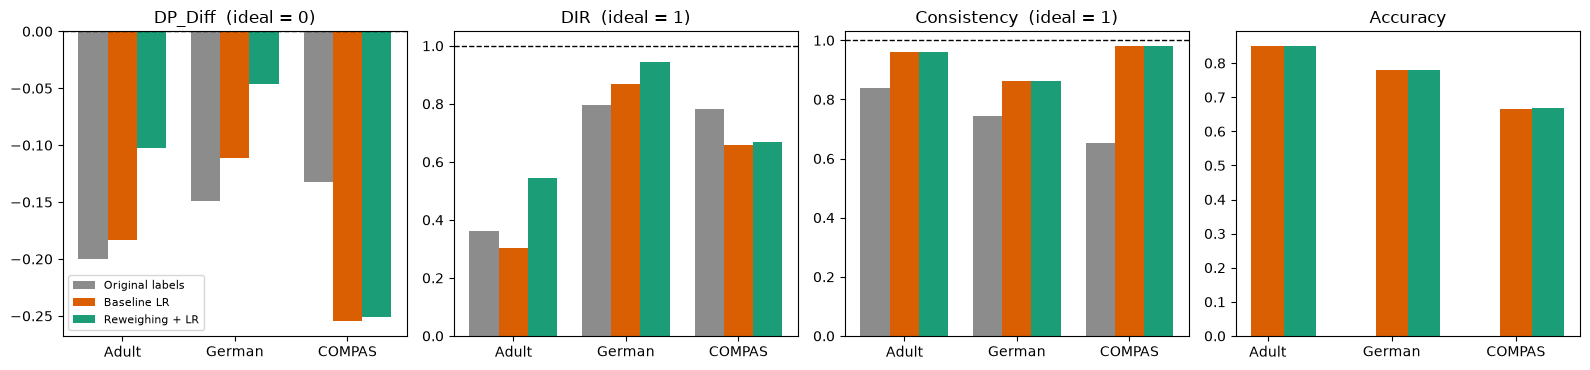

In [9]:
stages = ["Original labels (full data)", "Test: baseline LR", "Test: Reweighing + LR"]
labels = ["Original labels", "Baseline LR", "Reweighing + LR"]
colors = ["#8c8c8c", "#d95f02", "#1b9e77"]
metrics = [("DP_Diff", 0.0), ("DIR", 1.0), ("Consistency", 1.0), ("Accuracy", None)]

fig, axes = plt.subplots(1, len(metrics), figsize=(16, 3.8))
names = list(all_results)
xpos = np.arange(len(names))
for ax, (metric, ideal) in zip(axes, metrics):
    for i, (stage, lab, col) in enumerate(zip(stages, labels, colors)):
        vals = [all_results[n].loc[stage, metric] for n in names]
        if metric == "Accuracy" and i == 0:
            continue  # accuracy is not defined for the original labels
        ax.bar(xpos + (i - 1) * 0.26, vals, width=0.26, label=lab, color=col)
    if ideal is not None:
        ax.axhline(ideal, color="black", linestyle="--", linewidth=1)
    ax.set_xticks(xpos)
    ax.set_xticklabels(names)
    ax.set_title(metric + ("" if ideal is None else f"  (ideal = {ideal:g})"))
axes[0].legend(fontsize=8, loc="best")
plt.tight_layout()
plt.savefig("results/before_after.png", dpi=200, bbox_inches="tight")
plt.show()

## 7. Robustness check over several random splits

A single split can be lucky or unlucky, especially on the small German dataset. The cell below repeats the experiment with different seeds and reports mean ± standard deviation of the test-set results.

In [10]:
rows = []
for name, df in datasets.items():
    for seed in range(N_REPEATS):
        res = run_experiment(df, seed=seed)
        for stage in stages[1:]:
            rows.append({"Dataset": name, "Stage": stage, "seed": seed, **res.loc[stage].to_dict()})
rep = pd.DataFrame(rows)
agg = rep.drop(columns="seed").groupby(["Dataset", "Stage"], sort=False).agg(["mean", "std"])
pretty = pd.DataFrame({m: agg[m]["mean"].map("{:.3f}".format) + " ± " + agg[m]["std"].map("{:.3f}".format)
                       for m in ["DP_Diff", "DIR", "Consistency", "Accuracy", "Balanced acc."]})
pretty.to_csv("results/results_repeated.csv")
pretty

DP_Diff            DIR    Consistency  \
Dataset Stage                                                                 
Adult   Test: baseline LR      -0.182 ± 0.005  0.316 ± 0.016  0.959 ± 0.002   
        Test: Reweighing + LR  -0.096 ± 0.005  0.573 ± 0.019  0.958 ± 0.001   
German  Test: baseline LR      -0.134 ± 0.052  0.834 ± 0.063  0.823 ± 0.014   
        Test: Reweighing + LR  -0.107 ± 0.051  0.868 ± 0.061  0.827 ± 0.015   
COMPAS  Test: baseline LR      -0.235 ± 0.023  0.685 ± 0.030  0.976 ± 0.004   
        Test: Reweighing + LR  -0.224 ± 0.024  0.703 ± 0.031  0.977 ± 0.003   

                                    Accuracy  Balanced acc.  
Dataset Stage                                                
Adult   Test: baseline LR      0.849 ± 0.003  0.770 ± 0.004  
        Test: Reweighing + LR  0.844 ± 0.004  0.753 ± 0.005  
German  Test: baseline LR      0.755 ± 0.016  0.669 ± 0.017  
        Test: Reweighing + LR  0.759 ± 0.012  0.671 ± 0.019  
COMPAS  Test: baseline LR      0.678 ± 0.005  0.673 ± 0.005  
        Test: Reweighing + LR  0.676 ± 0.007  0.670 ± 0.007